# ДЗ #1. Дообучение с итеративной аугментацией, разморозкой слоёв и псевдолейблингом

**Задание.** Найти и согласовать с преподавателем датасет. Обучить как минимум 2 разных архитектуры сетей,
используя разобранные на занятии техники:

- итеративная аугментация;
- итеративная разморозка слоёв с адаптивным lr;
- псевдолейблинг.

**Датасет (согласован):** [EuroSAT RGB](https://github.com/phelber/EuroSAT): 27 000 спутниковых снимков
Sentinel-2 размером 64×64, 10 классов землепользования.

**Постановка.** Полу-supervised сценарий: разметка оставлена только у 10% обучающей выборки, остальные 90% —
неразмеченный пул для псевдолейблинга. Истинные метки пула в обучение не попадают и используются только для
оценки качества псевдометок.

**Архитектуры** (обе предобучены на ImageNet, берутся из `timm`):

- **ConvNeXt-T** — современная свёрточная сеть (28M параметров);
- **DeiT-S** — vision transformer (22M параметров).

**Эксперименты** для каждой архитектуры:

1. *Baseline* — сразу размораживаем всю сеть, без аугментаций, один lr для всех слоёв.
2. *Итеративная разморозка + итеративная аугментация* — 4 стадии, на каждой размораживается больше слоёв,
   растёт сила аугментаций, lr — дискриминативный по слоям и адаптируется к validation loss.
3. *+ Псевдолейблинг* — 3 раунда self-training поверх модели из п. 2.
4. *Все метки* — пайплайн п. 2 на полностью размеченной выборке: верхняя граница для п. 1–3.

Код вынесен в пакет `eurosat_ssl/` и покрыт тестами (`tests/`). Ноутбук рассчитан на запуск на GPU
(Kaggle / Colab): первая ячейка сама скачивает код из репозитория, если ноутбук открыт вне него.

In [1]:
import subprocess
import sys
from pathlib import Path

REPOSITORY_URL = "https://github.com/Hisoka742/applied-ml-course.git"
REPOSITORY_BRANCH = "hw1_finetuning_pseudolabeling"
CLONE_DIR = Path("applied-ml-course")

# On Kaggle / Colab the notebook is opened outside the repository, so the package is cloned next to it.
if not Path("eurosat_ssl").exists():
    if not CLONE_DIR.exists():
        clone_command = [
            "git",
            "clone",
            "--depth",
            "1",
            "--branch",
            REPOSITORY_BRANCH,
            REPOSITORY_URL,
            str(CLONE_DIR),
        ]
        subprocess.run(clone_command, check=True)
    sys.path.insert(0, str(CLONE_DIR / "hw1_finetuning_pseudolabeling"))

Cloning into 'applied-ml-course'...


In [2]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

In [3]:
from eurosat_ssl.augmentations import AUGMENTATION_LEVEL_NAMES, build_augmentation
from eurosat_ssl.data import SplitConfig, load_eurosat, make_splits
from eurosat_ssl.experiments import (
    ExperimentResult,
    class_prior,
    eval_loader,
    evaluate_on_test,
    make_trainer,
    results_table,
    train_set_factory,
)
from eurosat_ssl.models import CONVNEXT_TINY, DEIT_SMALL, ArchitectureSpec
from eurosat_ssl.plotting import plot_run
from eurosat_ssl.pseudo_labeling import PseudoLabelingConfig, self_train
from eurosat_ssl.training import Stage, TrainConfig, Trainer, TrainSetFactory

In [4]:
SEED = 42
DATA_ROOT = Path("data")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# SMOKE_TEST=1 runs the whole notebook on a small subset with few epochs to check the code on CPU.
SMOKE_TEST = os.environ.get("SMOKE_TEST") == "1"

ARCHITECTURES = [CONVNEXT_TINY, DEIT_SMALL]
IMAGE_SIZE = 64 if SMOKE_TEST else 160
SPLIT_CONFIG = SplitConfig(test_share=0.2, val_share=0.05, labeled_share=0.1, seed=SEED)
TRAIN_CONFIG = TrainConfig(batch_size=128, num_workers=0 if SMOKE_TEST else 2, seed=SEED)
# Epoch limits are upper bounds: every stage stops early when the validation loss stops improving.
MAX_EPOCHS_SCALE = 0.05 if SMOKE_TEST else 1.0


def epochs(n_epochs: int) -> int:
    return max(1, round(n_epochs * MAX_EPOCHS_SCALE))


BASELINE_STAGES = [
    Stage(
        "baseline",
        n_unfrozen_groups=None,
        augmentation_level=0,
        base_lr=1e-4,
        max_epochs=epochs(40),
        lr_decay=1.0,
        patience=4,
    ),
]
PROGRESSIVE_STAGES = [
    Stage(
        "1: head", n_unfrozen_groups=1, augmentation_level=0, base_lr=1e-3, max_epochs=epochs(10), patience=2
    ),
    Stage("2: + top group", n_unfrozen_groups=2, augmentation_level=1, base_lr=5e-4, max_epochs=epochs(10)),
    Stage("3: + 2 groups", n_unfrozen_groups=3, augmentation_level=2, base_lr=3e-4, max_epochs=epochs(15)),
    Stage(
        "4: all layers",
        n_unfrozen_groups=None,
        augmentation_level=3,
        base_lr=1e-4,
        max_epochs=epochs(25),
        patience=4,
    ),
]
STUDENT_STAGE = Stage(
    "pseudo-labels", n_unfrozen_groups=None, augmentation_level=3, base_lr=5e-5, max_epochs=epochs(10)
)
PSEUDO_LABELING_CONFIG = PseudoLabelingConfig(
    thresholds=(0.95, 0.9, 0.8), class_balance_slack=1.5, use_tta=True
)

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 4)
print(f"device: {DEVICE}, smoke test: {SMOKE_TEST}")

device: cuda, smoke test: False


## 1. Данные

In [5]:
eurosat = load_eurosat(DATA_ROOT)
if SMOKE_TEST:
    subset = torch.randperm(len(eurosat.labels), generator=torch.Generator().manual_seed(SEED))[:2000]
    eurosat.images, eurosat.labels = eurosat.images[subset], eurosat.labels[subset]

CLASS_NAMES = eurosat.class_names
N_CLASSES = len(CLASS_NAMES)
splits = make_splits(eurosat.labels, SPLIT_CONFIG)

split_sizes = pd.Series(
    {
        "labeled (train)": len(splits.labeled),
        "unlabeled (pool for pseudo-labels)": len(splits.unlabeled),
        "validation": len(splits.val),
        "test": len(splits.test),
    },
    name="images",
)
print(f"images: {tuple(eurosat.images.shape)}, dtype: {eurosat.images.dtype}")
split_sizes.to_frame()

100%|██████████| 94.3M/94.3M [00:00<00:00, 94.8MB/s]


images: (27000, 3, 64, 64), dtype: torch.uint8


,images
labeled (train),2025
unlabeled (pool for pseudo-labels),18225
validation,1350
test,5400


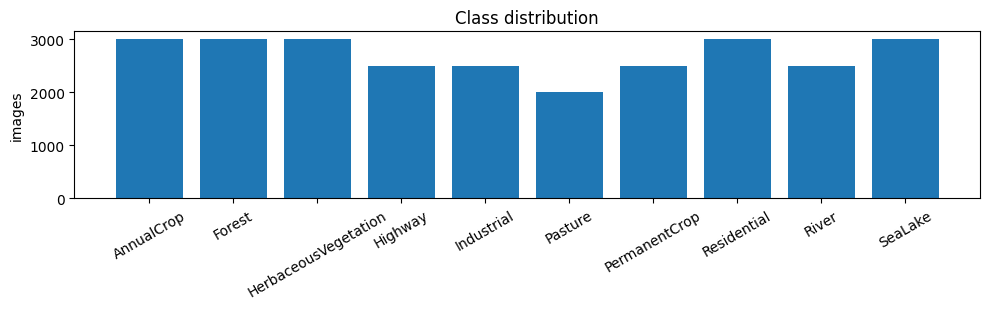

In [6]:
class_counts = pd.Series(np.bincount(eurosat.labels.numpy(), minlength=N_CLASSES), index=CLASS_NAMES)

figure, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(CLASS_NAMES, class_counts.to_numpy())
ax.set_ylabel("images")
ax.set_title("Class distribution")
ax.tick_params(axis="x", labelrotation=30)
figure.tight_layout()
plt.show()

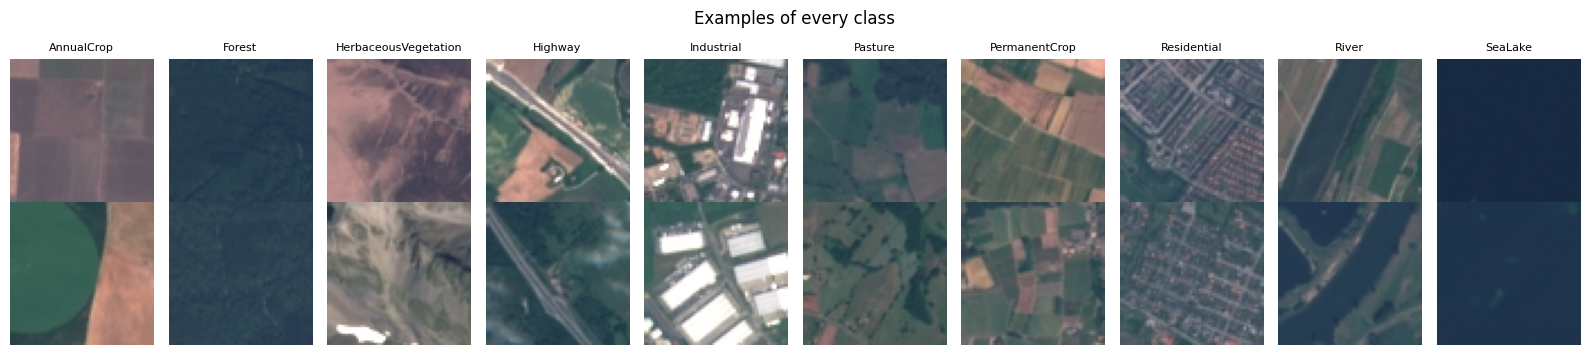

In [7]:
figure, axes = plt.subplots(2, N_CLASSES, figsize=(N_CLASSES * 1.6, 3.6))
for class_index, class_name in enumerate(CLASS_NAMES):
    examples = torch.nonzero(eurosat.labels == class_index).flatten()[:2]
    for row, image_index in enumerate(examples):
        axes[row, class_index].imshow(eurosat.images[image_index].permute(1, 2, 0).numpy())
        axes[row, class_index].axis("off")
    axes[0, class_index].set_title(class_name, fontsize=8)
figure.suptitle("Examples of every class")
figure.tight_layout()
plt.show()

**Ожидаемое качество.** Авторы датасета (Helber et al., 2019) получают ≈98.6% accuracy на RGB-версии,
дообучая ResNet-50 на 80% размеченных данных. Наша постановка с 10% разметки сложнее, поэтому разумный
ориентир — 95–97% для полуразмеченных экспериментов и ≈98–99% для эксперимента со всеми метками.

## 2. Итеративная аугментация

Уровни аугментаций нарастают от стадии к стадии. Сначала модель учится на чистых снимках, а по мере
разморозки (и роста числа обучаемых параметров, то есть риска переобучения) аугментации становятся сильнее:

| Уровень | Преобразования |
|---|---|
| 0 | нет |
| 1 | отражения по горизонтали и вертикали, поворот на 90°·k (у снимков нет «верха», класс не меняется) |
| 2 | + RandomResizedCrop (масштаб 0.6–1), ColorJitter |
| 3 | + RandAugment, RandomErasing |

Аугментации применяются на CPU к uint8-снимкам 64×64, а ресайз до входного размера модели и нормализация
выполняются на GPU сразу для всего батча.

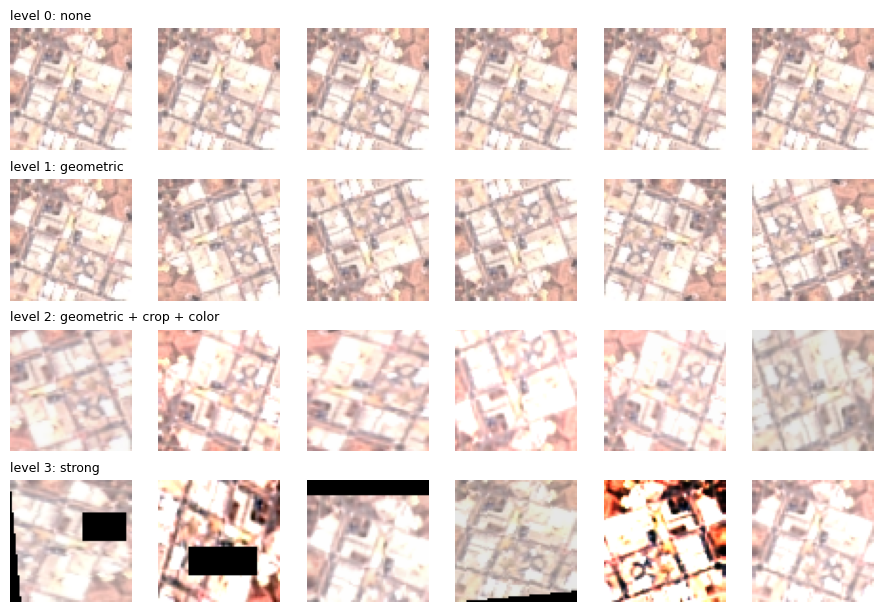

In [8]:
example = eurosat.images[splits.labeled[0]]
n_samples = 6
torch.manual_seed(SEED)

figure, axes = plt.subplots(len(AUGMENTATION_LEVEL_NAMES), n_samples, figsize=(n_samples * 1.5, 6.2))
for level, level_name in enumerate(AUGMENTATION_LEVEL_NAMES):
    augmentation = build_augmentation(level)
    for column in range(n_samples):
        axes[level, column].imshow(augmentation(example).permute(1, 2, 0).numpy())
        axes[level, column].axis("off")
    axes[level, 0].set_title(f"level {level}: {level_name}", fontsize=9, loc="left")
figure.tight_layout()
plt.show()

## 3. Итеративная разморозка слоёв с адаптивным lr

Каждая сеть разбита на 5 групп слоёв от головы к входу:

- **ConvNeXt-T:** голова → stage 4 → stage 3 → stage 2 → stage 1 + stem;
- **DeiT-S:** голова + финальная нормализация → блоки 10–12 → 7–9 → 4–6 → 1–3 + patch embedding и позиционные эмбеддинги.

Обучение идёт по стадиям (`PROGRESSIVE_STAGES`): голова → + 1 группа → + 2 группы → вся сеть. Адаптивность lr:

- **дискриминативный lr**: у группы на расстоянии $i$ от головы lr $= \text{base\_lr} \cdot 0.5^{\,i}$, так как
  нижние слои содержат общие признаки и их нужно менять меньше;
- **base_lr уменьшается** от стадии к стадии (1e-3 → 1e-4): чем больше обучаемых параметров, тем осторожнее шаг;
- **ReduceLROnPlateau** внутри стадии: lr умножается на 0.3, если validation loss не улучшился;
- **ранняя остановка** стадии по validation loss; следующая стадия стартует с лучших весов.

Baseline: вся сеть сразу, без аугментаций, один lr для всех слоёв (`lr_decay=1`), остальное то же самое.

In [9]:
labeled_set = train_set_factory(eurosat, splits.labeled)
all_labels_set = train_set_factory(eurosat, np.concatenate([splits.labeled, splits.unlabeled]))
val_loader = eval_loader(eurosat, splits.val, TRAIN_CONFIG)
test_loader = eval_loader(eurosat, splits.test, TRAIN_CONFIG)
test_labels = eurosat.labels[splits.test]
labeled_prior = class_prior(eurosat.labels[splits.labeled], N_CLASSES)

results = []


def show_result(result: ExperimentResult) -> None:
    """Same report for every run: learning curves, confusion matrix and test metrics."""
    title = f"{result.architecture}: {result.setup}"
    plot_run(result.history, test_labels.numpy(), result.test_predictions, CLASS_NAMES, title)
    plt.show()
    print(", ".join(f"{name}: {value:.4f}" for name, value in result.metrics.items()))


def train_and_report(
    spec: ArchitectureSpec, setup: str, stages: list[Stage], make_train_set: TrainSetFactory
) -> Trainer:
    """Trains a fresh pretrained model through ``stages`` and reports it on the test set."""
    start = time.perf_counter()
    trainer = make_trainer(spec, N_CLASSES, IMAGE_SIZE, TRAIN_CONFIG, DEVICE)
    trainer.fit(stages, make_train_set, val_loader)
    result = evaluate_on_test(trainer, test_loader, test_labels, spec.name, setup)
    result.metrics["minutes"] = (time.perf_counter() - start) / 60
    results.append(result)
    show_result(result)
    return trainer

### 3.1. Baseline

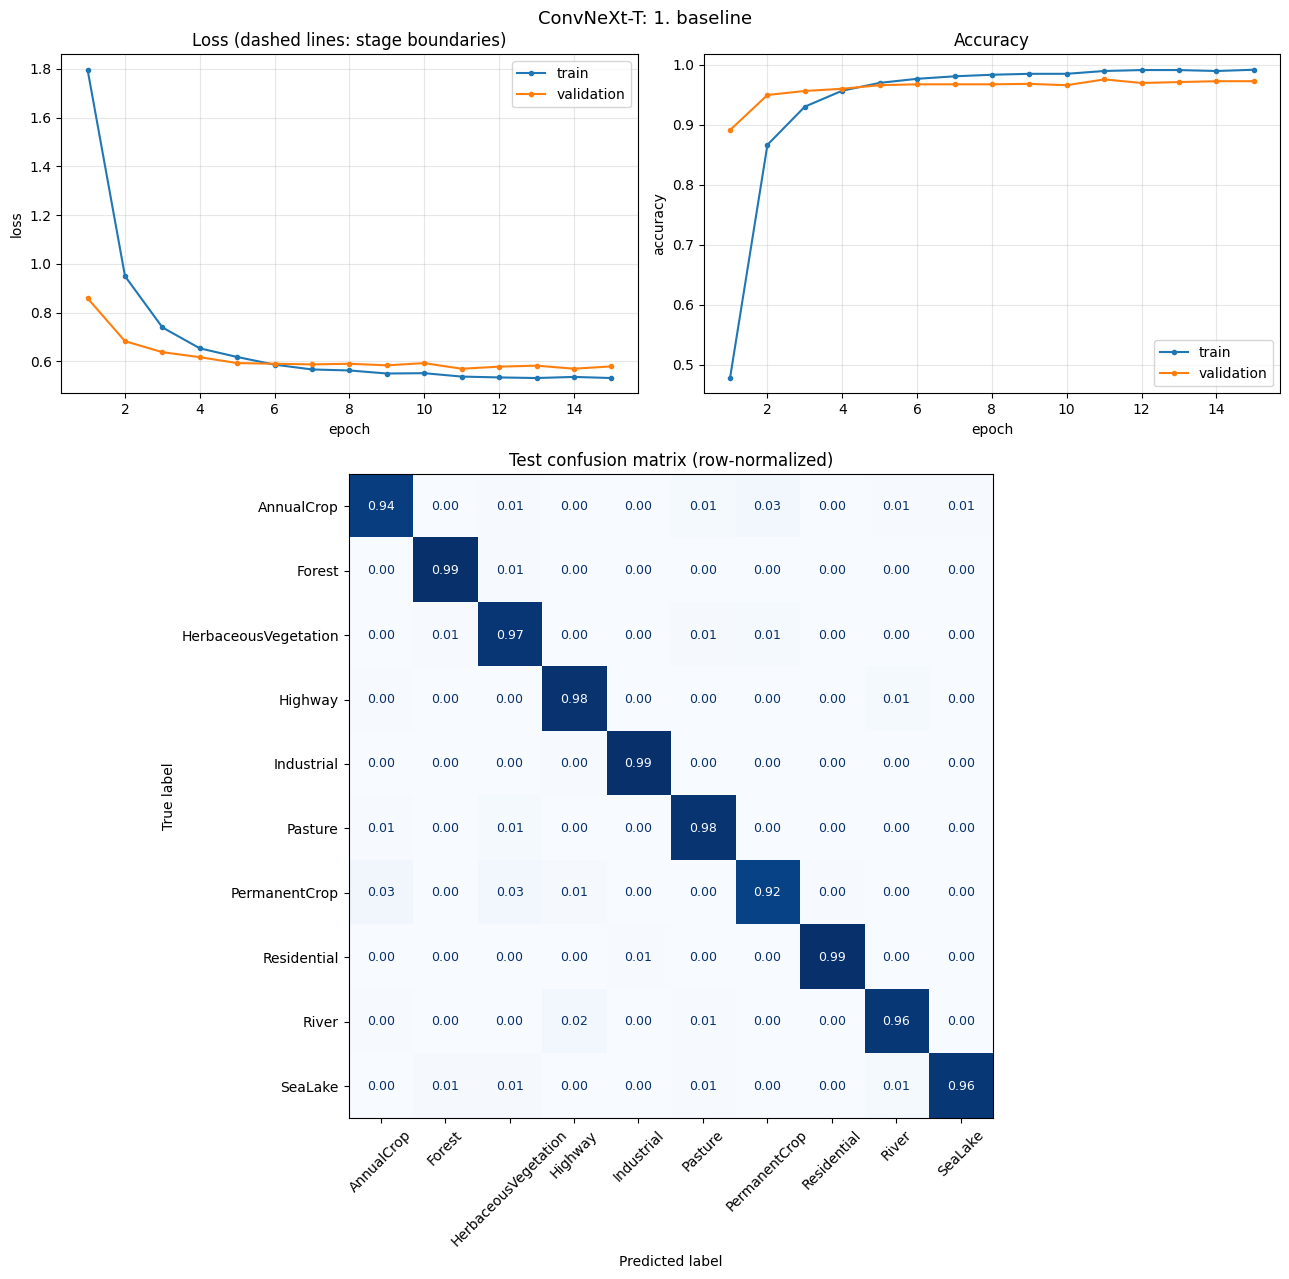

test_accuracy: 0.9702, test_macro_f1: 0.9696, epochs: 15.0000, minutes: 1.8640


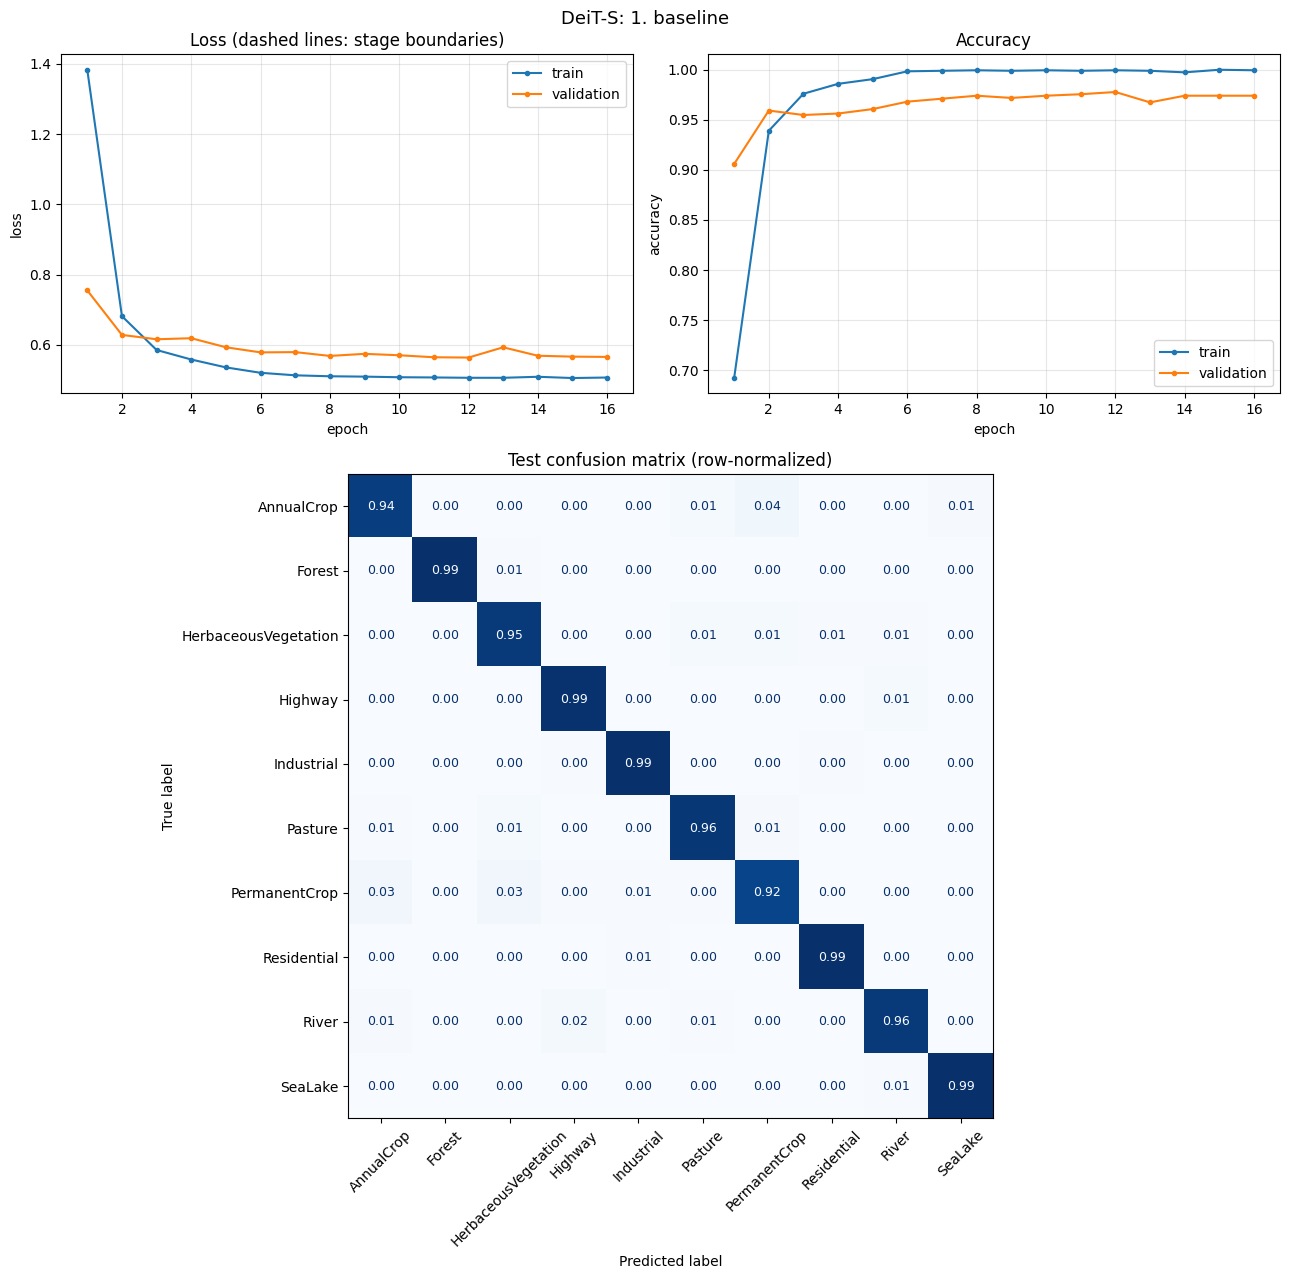

test_accuracy: 0.9693, test_macro_f1: 0.9683, epochs: 16.0000, minutes: 0.9786


In [10]:
for spec in ARCHITECTURES:
    train_and_report(spec, "1. baseline", BASELINE_STAGES, labeled_set)
    torch.cuda.empty_cache()

### 3.2. Итеративная разморозка + итеративная аугментация

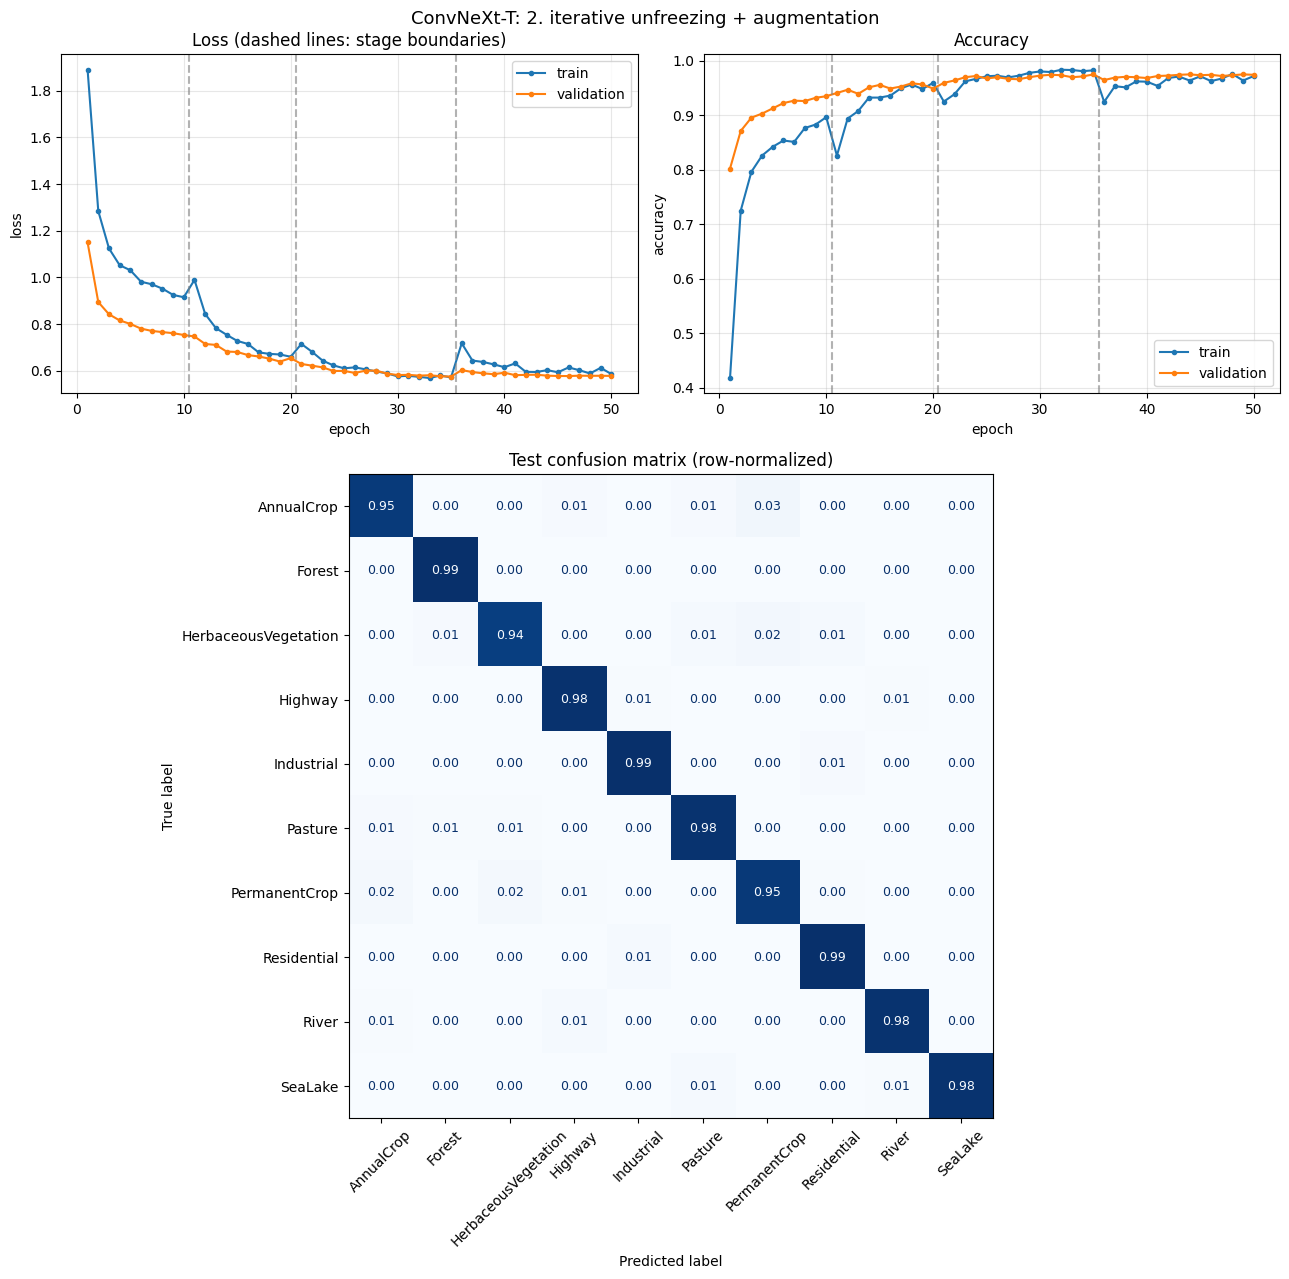

test_accuracy: 0.9728, test_macro_f1: 0.9723, epochs: 50.0000, minutes: 3.6061


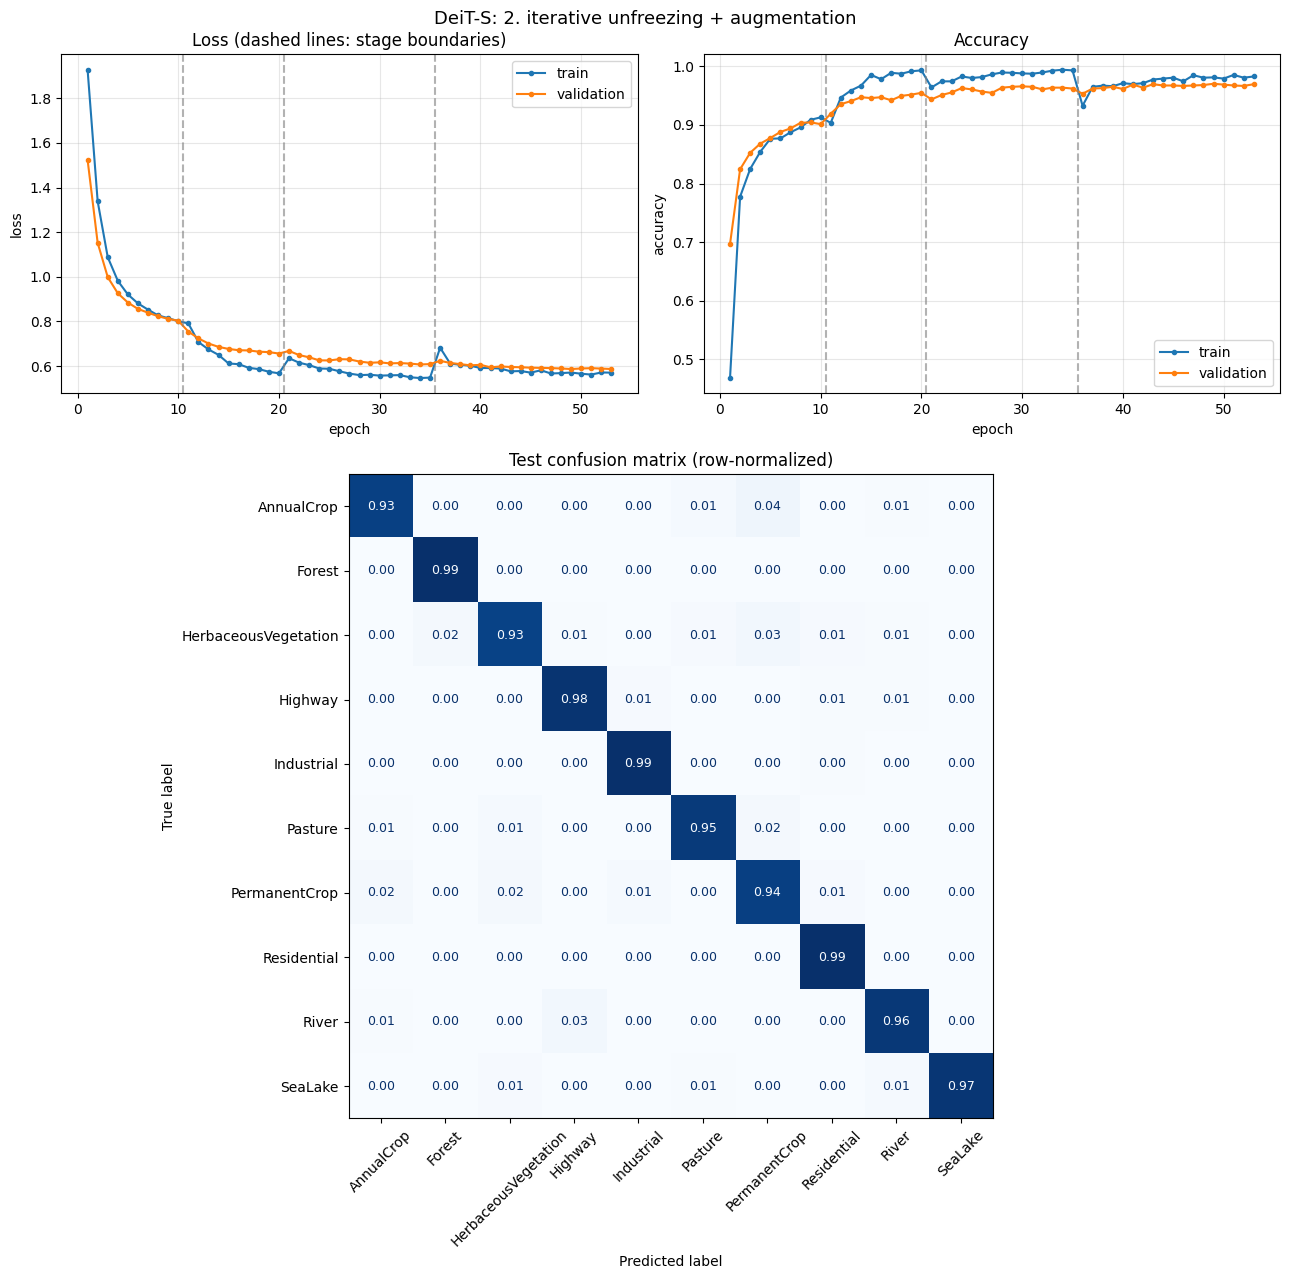

test_accuracy: 0.9637, test_macro_f1: 0.9630, epochs: 53.0000, minutes: 2.4396


In [11]:
progressive_trainers = {}
for spec in ARCHITECTURES:
    progressive_trainers[spec.name] = train_and_report(
        spec, "2. iterative unfreezing + augmentation", PROGRESSIVE_STAGES, labeled_set
    )

In [12]:
stage_summary = pd.concat(
    {
        name: trainer.history_frame()
        .groupby("stage", sort=False)
        .agg(
            epochs=("epoch", "size"),
            unfrozen_groups=("unfrozen_groups", "first"),
            augmentation_level=("augmentation_level", "first"),
            start_lr=("lr", "first"),
            end_lr=("lr", "last"),
            best_val_loss=("val_loss", "min"),
            best_val_accuracy=("val_accuracy", "max"),
        )
        for name, trainer in progressive_trainers.items()
    },
    names=["architecture"],
)
stage_summary

epochs  unfrozen_groups  augmentation_level  \
architecture stage                                                         
ConvNeXt-T   1: head             10                1                   0   
             2: + top group      10                2                   1   
             3: + 2 groups       15                3                   2   
             4: all layers       15                5                   3   
DeiT-S       1: head             10                1                   0   
             2: + top group      10                2                   1   
             3: + 2 groups       15                3                   2   
             4: all layers       18                5                   3   

                             start_lr      end_lr  best_val_loss  \
architecture stage                                                 
ConvNeXt-T   1: head           0.0010  1.0000e-03         0.7532   
             2: + top group    0.0005  5.0000e-04         0.6393   
             3: + 2 groups     0.0003  9.0000e-05         0.5750   
             4: all layers     0.0001  9.0000e-06         0.5772   
DeiT-S       1: head           0.0010  1.0000e-03         0.8033   
             2: + top group    0.0005  5.0000e-04         0.6564   
             3: + 2 groups     0.0003  9.0000e-05         0.6073   
             4: all layers     0.0001  9.0000e-06         0.5870   

                             best_val_accuracy  
architecture stage                              
ConvNeXt-T   1: head                    0.9348  
             2: + top group             0.9585  
             3: + 2 groups              0.9748  
             4: all layers              0.9748  
DeiT-S       1: head                    0.9044  
             2: + top group             0.9548  
             3: + 2 groups              0.9659  
             4: all layers              0.9704

## 4. Псевдолейблинг

Self-training поверх моделей из п. 3.2, 3 раунда:

1. текущая модель предсказывает неразмеченный пул с TTA (усреднение по 4 ориентациям снимка);
2. в псевдометки берутся предсказания с уверенностью не ниже порога (0.95 → 0.9 → 0.8 по раундам);
   число псевдометок на класс ограничено (не более чем в 1.5 раза больше доли класса в размеченной выборке),
   чтобы модель не «сползала» в лёгкие классы;
3. вся сеть дообучается на размеченных + псевдоразмеченных снимках с сильными аугментациями (уровень 3) и
   малым lr; если раунд не улучшил validation loss, остаются веса предыдущего.

Точность псевдометок считается по скрытым истинным меткам пула и в обучении не используется; test accuracy по
раундам — только для отчёта.

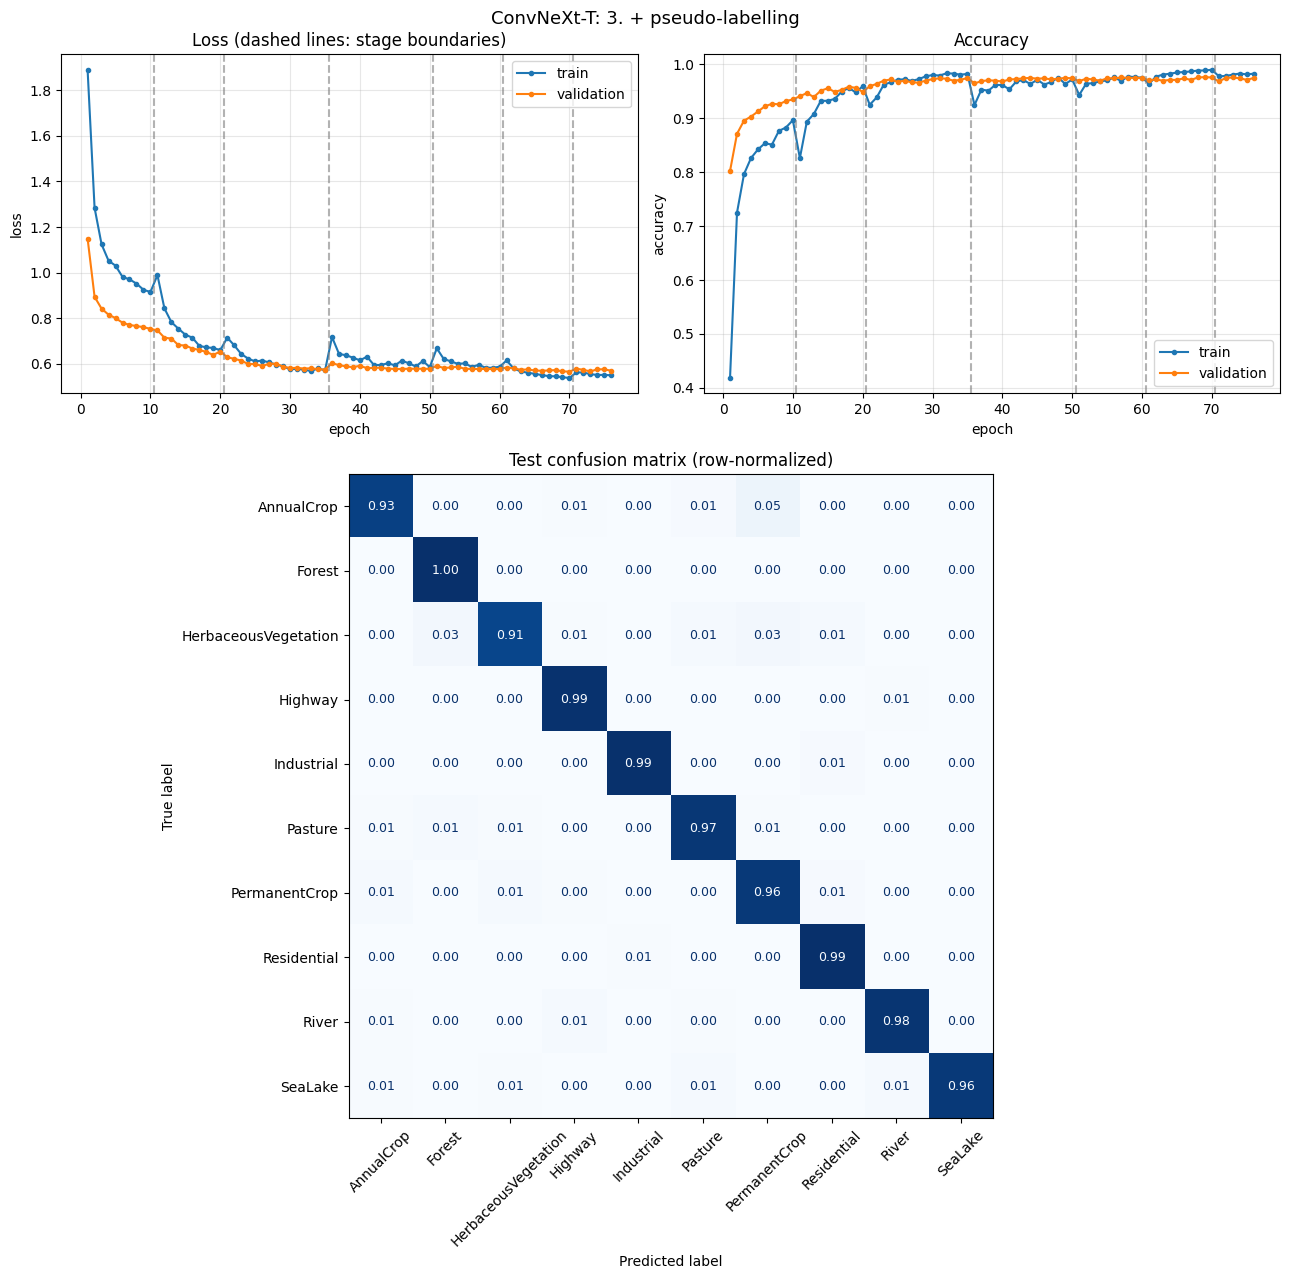

test_accuracy: 0.9665, test_macro_f1: 0.9661, epochs: 76.0000, minutes: 16.2149


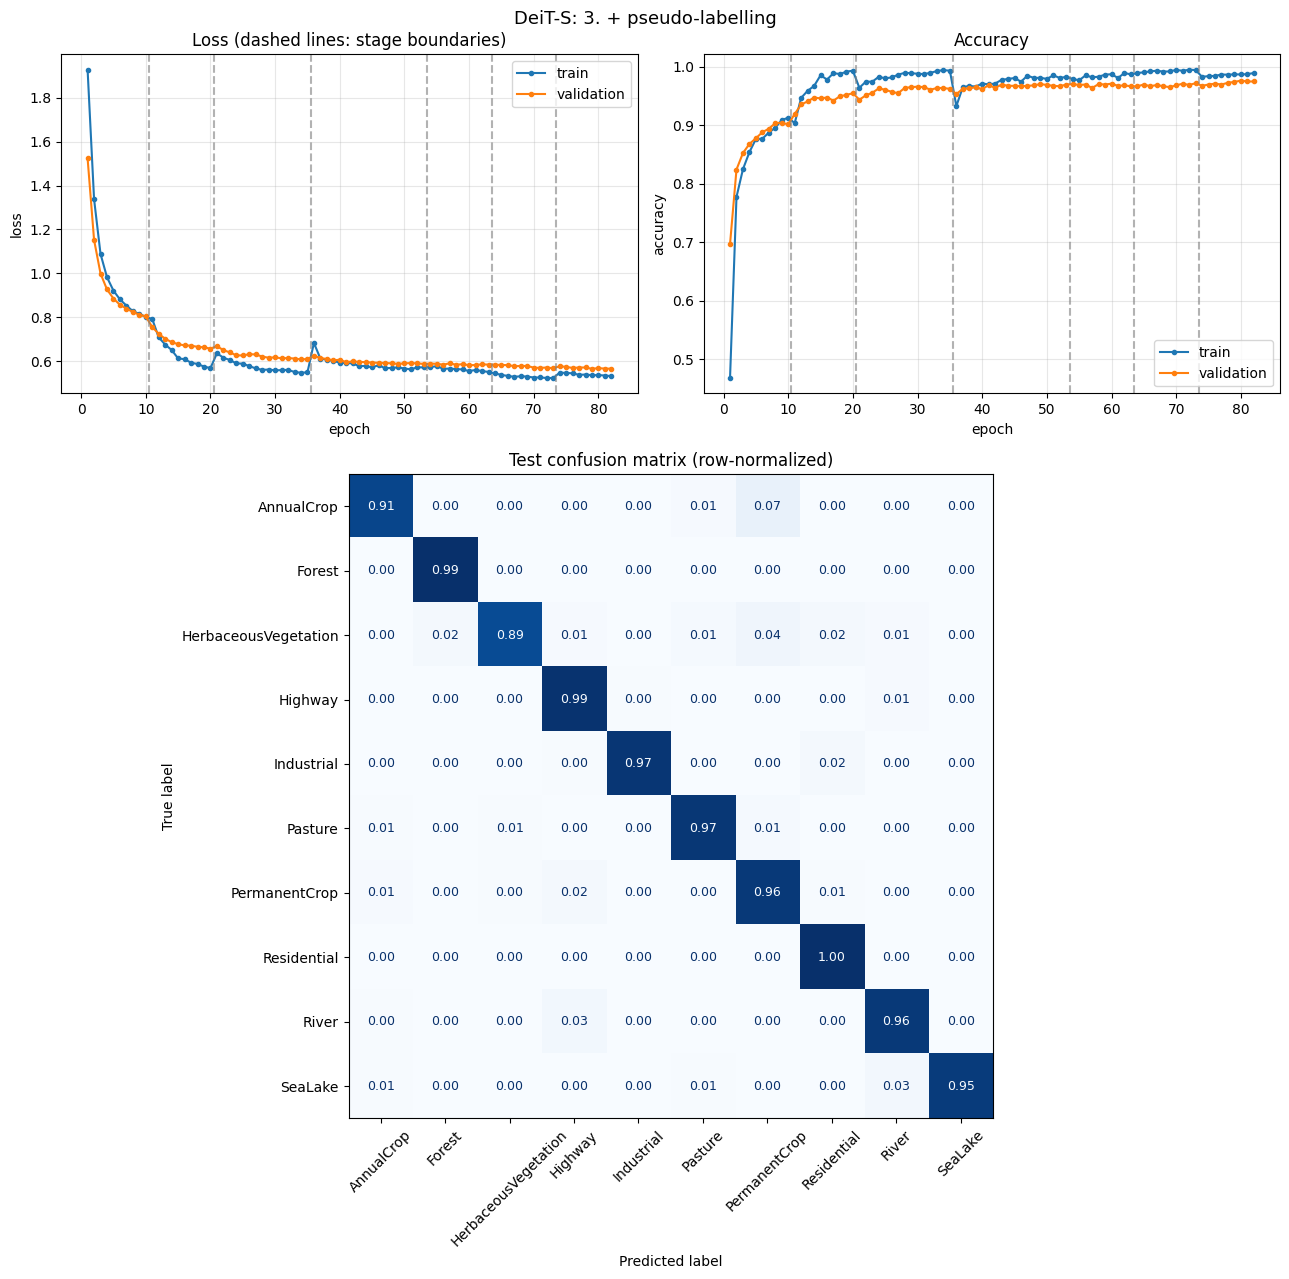

test_accuracy: 0.9594, test_macro_f1: 0.9591, epochs: 82.0000, minutes: 10.1194


threshold  n_pseudo_labels  share_of_unlabeled_pool  \
architecture round                                                        
ConvNeXt-T   1           0.95             2302                   0.1263   
             2           0.90            13537                   0.7428   
             3           0.80            17028                   0.9343   
DeiT-S       1           0.95              912                   0.0500   
             2           0.90            10663                   0.5851   
             3           0.80            16899                   0.9272   

                    pseudo_label_accuracy  val_loss  val_accuracy  \
architecture round                                                  
ConvNeXt-T   1                     0.9991    0.5750        0.9748   
             2                     0.9983    0.5656        0.9756   
             3                     0.9908    0.5656        0.9756   
DeiT-S       1                     0.9956    0.5810        0.9711   
             2                     0.9988    0.5672        0.9719   
             3                     0.9909    0.5646        0.9741   

                    test_accuracy  
architecture round                 
ConvNeXt-T   1             0.9728  
             2             0.9665  
             3             0.9665  
DeiT-S       1             0.9628  
             2             0.9637  
             3             0.9594

In [13]:
pseudo_label_rounds = {}
for spec in ARCHITECTURES:
    start = time.perf_counter()
    trainer = progressive_trainers[spec.name]
    pseudo_label_rounds[spec.name] = self_train(
        trainer,
        PSEUDO_LABELING_CONFIG,
        STUDENT_STAGE,
        labeled_set,
        eurosat.images[splits.unlabeled],
        eurosat.labels[splits.unlabeled],
        labeled_prior,
        val_loader,
        test_loader,
    )
    result = evaluate_on_test(trainer, test_loader, test_labels, spec.name, "3. + pseudo-labelling")
    result.metrics["minutes"] = (time.perf_counter() - start) / 60
    results.append(result)
    show_result(result)

pd.concat(pseudo_label_rounds, names=["architecture"]).droplevel(1).set_index("round", append=True)

In [14]:
del progressive_trainers
torch.cuda.empty_cache()

## 5. Верхняя граница: все метки

Тот же пайплайн из п. 3.2, но размечен весь обучающий пул (10% + 90%).

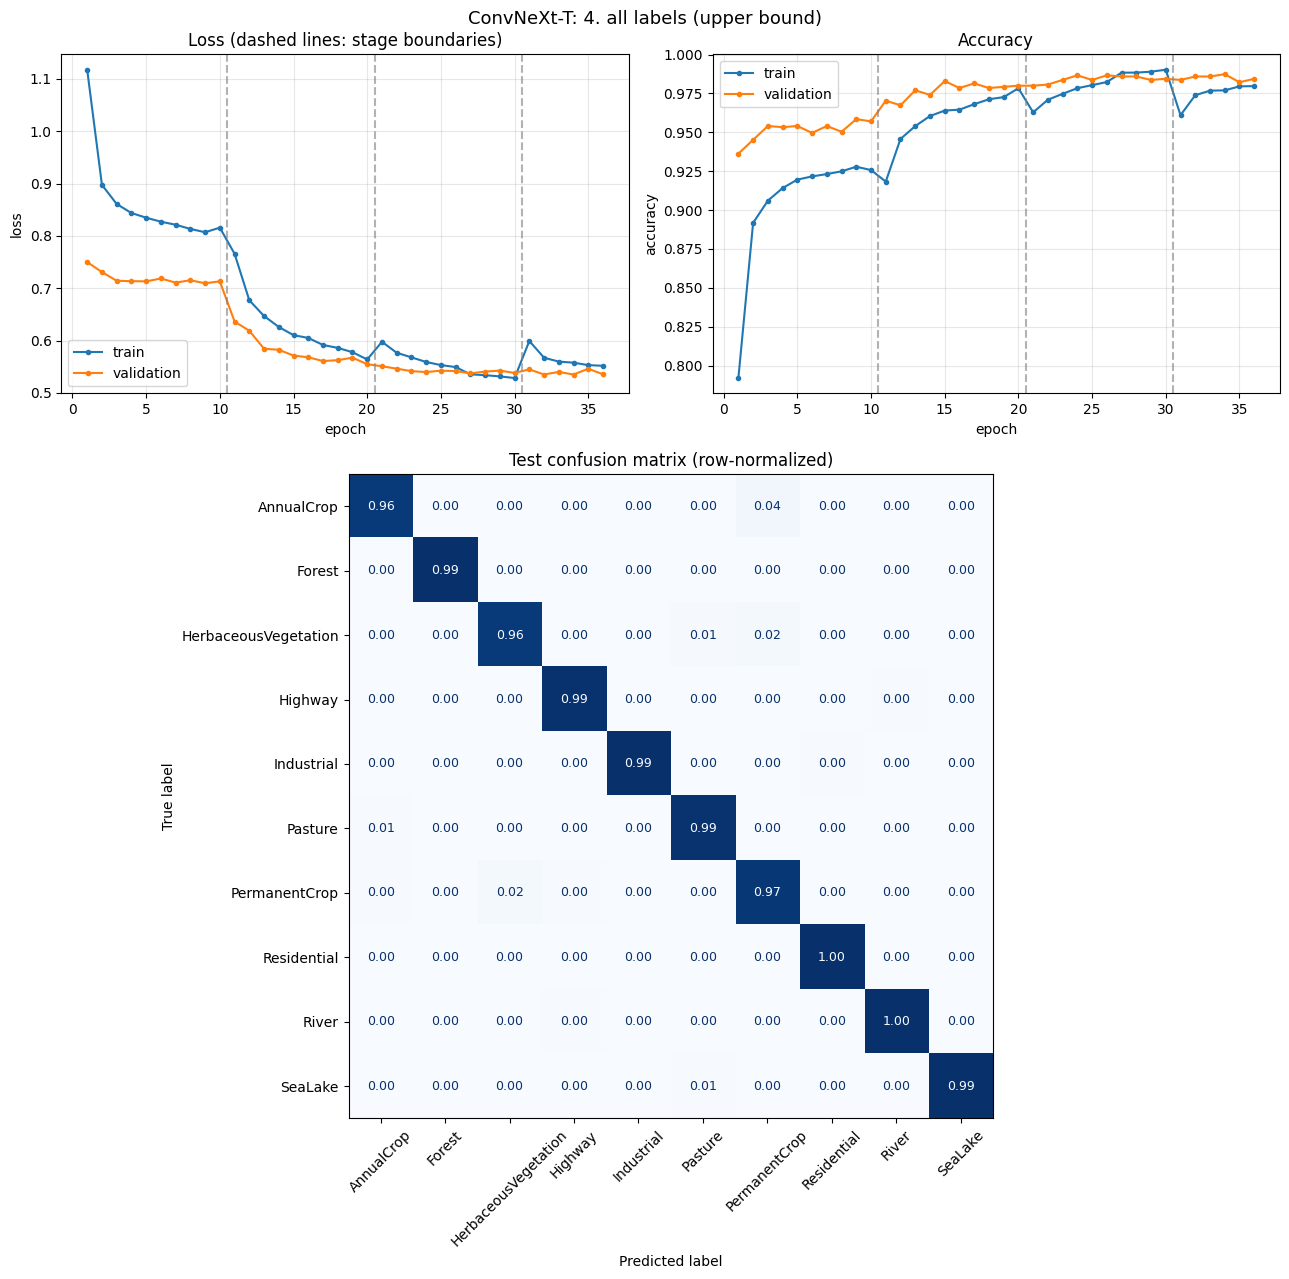

test_accuracy: 0.9848, test_macro_f1: 0.9845, epochs: 36.0000, minutes: 17.0334


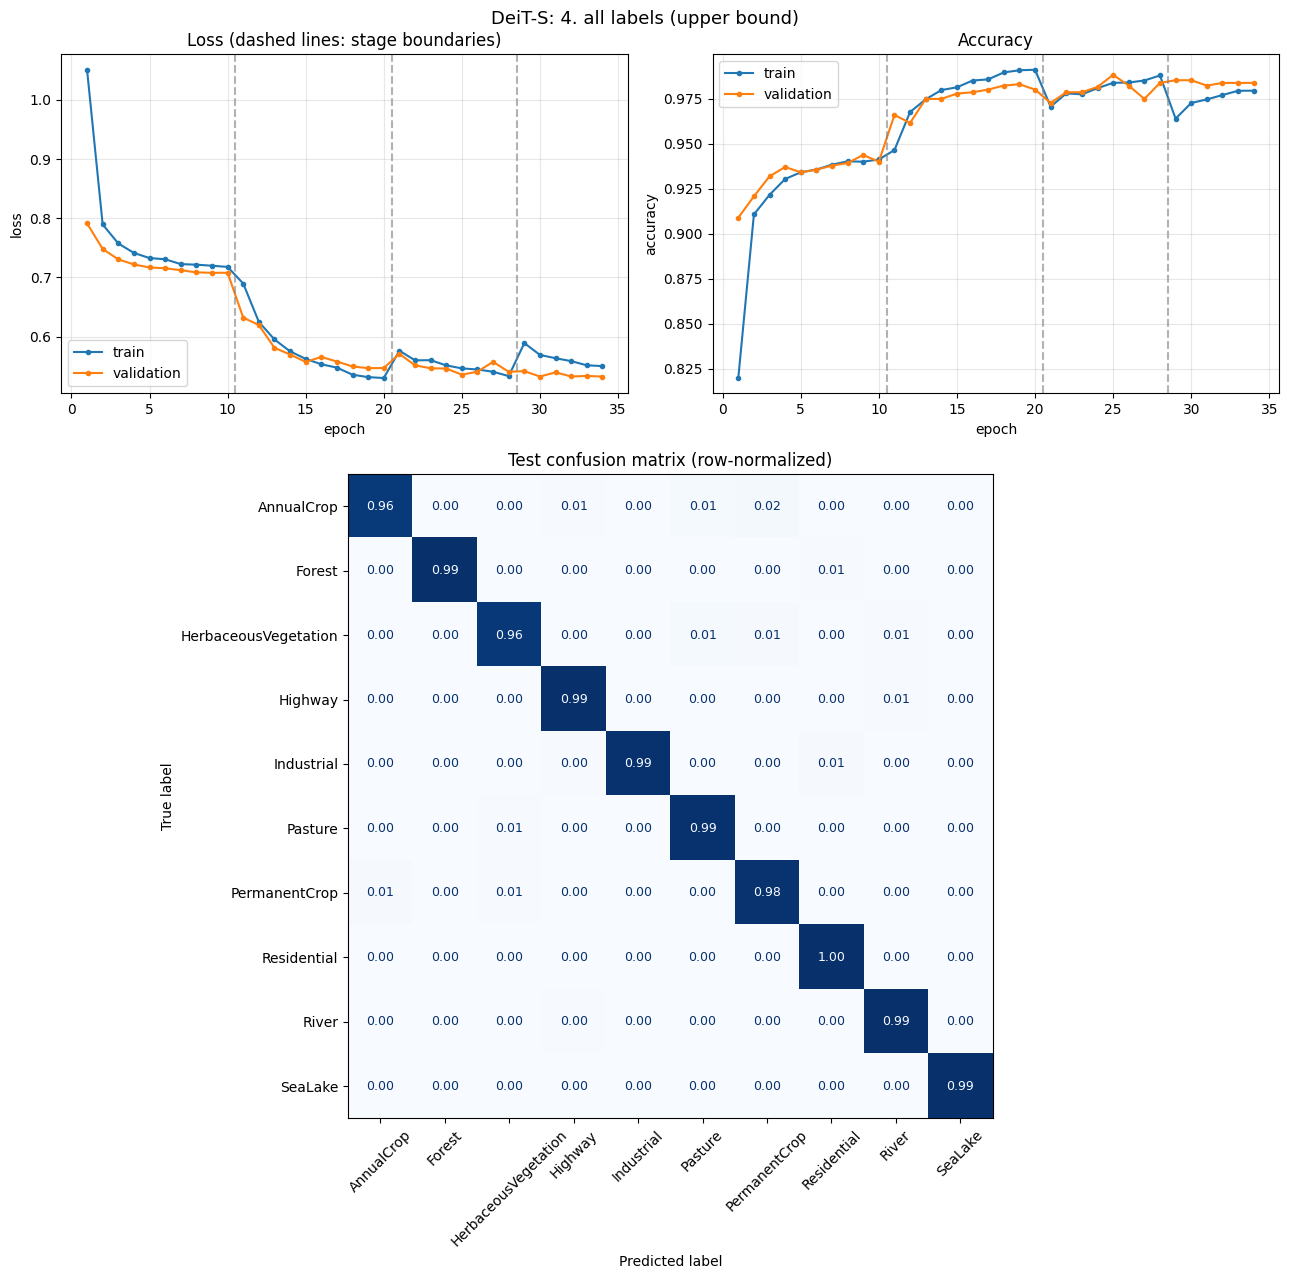

test_accuracy: 0.9837, test_macro_f1: 0.9832, epochs: 34.0000, minutes: 10.0986


In [15]:
for spec in ARCHITECTURES:
    train_and_report(spec, "4. all labels (upper bound)", PROGRESSIVE_STAGES, all_labels_set)
    torch.cuda.empty_cache()

## 6. Итоги

In [16]:
summary = results_table(results)
summary

,,test_accuracy,test_macro_f1,epochs,minutes
architecture,setup,,,,
ConvNeXt-T,1. baseline,0.9702,0.9696,15,1.8640
DeiT-S,1. baseline,0.9693,0.9683,16,0.9786
ConvNeXt-T,2. iterative unfreezing + augmentation,0.9728,0.9723,50,3.6061
DeiT-S,2. iterative unfreezing + augmentation,0.9637,0.9630,53,2.4396
ConvNeXt-T,3. + pseudo-labelling,0.9665,0.9661,76,16.2149
DeiT-S,3. + pseudo-labelling,0.9594,0.9591,82,10.1194
ConvNeXt-T,4. all labels (upper bound),0.9848,0.9845,36,17.0334
DeiT-S,4. all labels (upper bound),0.9837,0.9832,34,10.0986


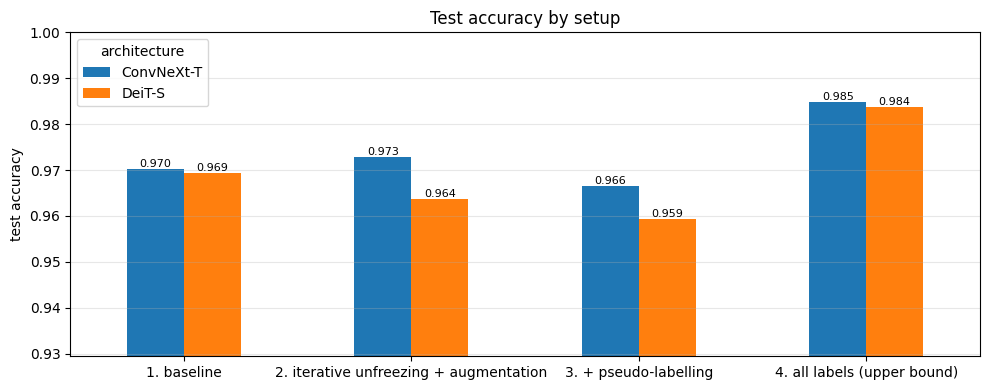

In [17]:
accuracy_table = summary["test_accuracy"].unstack("architecture")

figure, ax = plt.subplots(figsize=(10, 4))
accuracy_table.plot.bar(ax=ax, rot=0)
lower_bound = max(0.0, accuracy_table.min().min() - 0.03)
ax.set_ylim(lower_bound, 1.0)
ax.set_ylabel("test accuracy")
ax.set_xlabel("")
ax.set_title("Test accuracy by setup")
ax.grid(axis="y", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
figure.tight_layout()
plt.show()

## 7. Выводы

**Итоговые числа (test, 5400 снимков).**

| | ConvNeXt-T | DeiT-S |
|---|---|---|
| 1. Baseline (10% меток) | 97.02% | 96.93% |
| 2. Итеративная разморозка + аугментация | **97.28%** | 96.37% |
| 3. + Псевдолейблинг | 96.65% | 95.94% |
| 4. Все метки (верхняя граница) | 98.48% | 98.37% |

**Соответствие ожиданиям.** Полуразмеченные эксперименты попали в ожидаемый диапазон 95–97%, эксперимент со
всеми метками дал 98.4–98.5% при ожидаемых ≈98–99% и опубликованных 98.6% (у авторов датасета 80% разметки
против наших 75%). Разметка всего 10% выборки стоит около 1.2–1.4 п.п. accuracy.

**Точность сравнений.** Стандартная ошибка accuracy на 5400 тестовых снимках при уровне 97% составляет
≈0.23 п.п., а каждая конфигурация обучена с одним сидом. Поэтому разницы 0.3–0.6 п.п. между п. 1–3 — слабые
свидетельства (1–2σ), а значимым можно считать только отрыв верхней границы. Validation-выборка ещё меньше
(1350 снимков, один снимок = 0.074 п.п.).

**Итеративная разморозка + итеративная аугментация.**

- *ConvNeXt-T:* небольшой выигрыш над baseline (+0.26 п.п.) и лучший результат среди полуразмеченных
  экспериментов. По таблице стадий видно, что каждая разморозка добавляет качество (val accuracy 93.5% →
  95.9% → 97.5%), а последняя стадия со всей сетью и сильными аугментациями validation loss уже не улучшила:
  для свёрточной сети достаточно разморозить верхние стадии.
- *DeiT-S:* итоговый результат хуже baseline (−0.56 п.п.). Трансформер медленнее адаптируется с замороженным
  телом (голова: 90.4% val accuracy против 93.5% у ConvNeXt), и ему нужна последняя стадия с разморозкой
  всех блоков (+0.45 п.п. val). Вероятная причина отставания — дискриминативный lr ($0.5^{i}$) слишком сильно
  тормозит нижние блоки, а им для снимков 64×64, растянутых до 160×160, нужно перестроиться сильнее, чем для
  ImageNet-подобных картинок. Это гипотеза: проверить её можно, например, ослабив затухание lr до 0.7–0.8.
- Цена — время: обучение по стадиям в 2–2.5 раза дольше baseline.

**Псевдолейблинг.**

- Псевдометки получились очень точными: 99.1–99.9% по скрытым меткам при использовании до 93% пула, а
  validation loss и validation accuracy выросли (у DeiT-S — на 5 снимков из 1350).
- Тем не менее test accuracy *упала* у обеих архитектур: −0.63 п.п. у ConvNeXt-T и −0.43 п.п. у DeiT-S.
  Расхождение val и test показывает, что улучшения на маленькой validation-выборке в основном шумовые, а
  отбор раундов по ней не защищает от ухудшения на test.
- Почему так происходит — confirmation bias. Уверенные псевдометки — это снимки, которые модель и так
  классифицирует правильно, поэтому новой информации в них мало. Оставшийся ≈1% ошибок (≈150 снимков в
  последнем раунде) сосредоточен как раз на трудных парах классов, и модель закрепляет собственные ошибки.
  Это видно по матрице ошибок ConvNeXt-T: после псевдолейблинга recall HerbaceousVegetation снизился с 0.94
  до 0.91 (растут ошибки в Forest и PermanentCrop), AnnualCrop — с 0.95 до 0.93 (в PermanentCrop), а
  «лёгкий» Forest вырос до 1.00. Кроме того, псевдометок (≈17 000) в 8 раз больше, чем настоящих меток
  (2025), так что в последних раундах модель учится в основном на собственных предсказаниях.
- Ограничение числа псевдометок на класс сработало как задумано: сдвига всех предсказаний в один класс нет,
  деградация точечная, на похожих классах.
- Что можно попробовать дальше: мягкие псевдометки или дистилляцию вместо жёстких меток, меньший вес лосса
  на псевдометках, обучение нового «студента» с нуля на каждом раунде (Noisy Student), consistency
  regularization со слабой и сильной аугментацией (FixMatch), пороги уверенности отдельно по классам.

**Сравнение архитектур.** При полной разметке архитектуры почти равны (98.48% против 98.37%), а в
полуразмеченных экспериментах ConvNeXt-T стабильно немного лучше и проще дообучается по стадиям: его
свёрточные признаки переносятся на маленькие спутниковые снимки лучше, чем признаки ViT. DeiT-S при этом
обучается в 1.5–2 раза быстрее.

**Итог.** Лучшая полуразмеченная модель — ConvNeXt-T с итеративной разморозкой и аугментацией (97.28%).
Итеративная разморозка с адаптивным lr полезна для свёрточной сети и требует другой настройки для
трансформера. Псевдолейблинг с жёсткими метками при высокой базовой точности (≈97%) не дал прироста: модель
уже правильно предсказывает почти всё, что уверенно размечает, а на трудных примерах закрепляет свои ошибки.

**Предупреждения в выводе.** Единственное предупреждение — `You are sending unauthenticated requests to the
HF Hub` при скачивании весов из Hugging Face Hub: на Kaggle не задан `HF_TOKEN`. Оно касается только лимитов
скорости скачивания и на результаты не влияет. Индикаторы прогресса скачивания весов удалены из сохранённого
вывода, так как вне Jupyter они не отображаются.